# Frequent Itemset Mining and Association Rule Generation

**Mapped CO:** CO4  
**Algorithm:** Apriori  
**Dataset:** Sample Transaction Dataset

## Aim
To discover frequent itemsets and generate association rules from transactional data using the Apriori algorithm.

## Objectives
1. Understand frequent itemset mining.
2. Identify frequent itemsets using Apriori.
3. Generate association rules from frequent itemsets.
4. Evaluate rules using support, confidence, and lift.
5. Interpret the discovered rules.

## 1. Theory

Frequent itemset mining finds combinations of items that occur together frequently in a transaction database. Apriori uses the principle that **every non-empty subset of a frequent itemset must also be frequent**. Therefore, an itemset can be discarded when one of its subsets is infrequent.

For an itemset \(X\) and a rule \(A \rightarrow B\), where \(A \cap B = \varnothing\):

- **Support:** proportion of all transactions containing the itemset.

  \[\operatorname{support}(X)=\frac{\#\{t:X\subseteq t\}}{N}\]

- **Confidence:** proportion of transactions containing \(A\) that also contain \(B\).

  \[\operatorname{confidence}(A\rightarrow B)=\frac{\operatorname{support}(A\cup B)}{\operatorname{support}(A)}\]

- **Lift:** confidence divided by the support of the consequent.

  \[\operatorname{lift}(A\rightarrow B)=\frac{\operatorname{confidence}(A\rightarrow B)}{\operatorname{support}(B)}\]

**Lift interpretation:** lift > 1 indicates a positive association; lift = 1 indicates independence; lift < 1 indicates a negative association. A high confidence value alone does not necessarily mean a strong association, because the consequent may already be very common.

## 2. Dataset Description

The supplied sample contains five transactions:

| Transaction ID | Items Purchased |
|---|---|
| T1 | Milk, Bread, Butter |
| T2 | Bread, Butter |
| T3 | Milk, Bread |
| T4 | Milk, Butter |
| T5 | Milk, Bread, Butter, Eggs |

The default minimum support is set to **0.20** so that Eggs-related patterns, which occur in one of the five transactions, are included. The default minimum confidence is **0.60**. You can change both thresholds in the parameter cell below.

> **Note:** This is a very small demonstration dataset. The discovered patterns are useful for learning the algorithm, but should not be treated as reliable business conclusions.


## 3. Install and Import Required Libraries

The next cell installs the required packages in the active Jupyter environment. Run it once if the libraries are not already installed.

In [1]:
%pip install -q pandas matplotlib mlxtend

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 4. Create / Load the Transaction Dataset

In [3]:
transactions = [
    ["Milk", "Bread", "Butter"],                 # T1
    ["Bread", "Butter"],                         # T2
    ["Milk", "Bread"],                           # T3
    ["Milk", "Butter"],                          # T4
    ["Milk", "Bread", "Butter", "Eggs"]          # T5
]

transaction_df = pd.DataFrame({
    "Transaction ID": [f"T{i+1}" for i in range(len(transactions))],
    "Items Purchased": [", ".join(items) for items in transactions]
})

display(transaction_df)
print(f"Number of transactions: {len(transactions)}")
print("Dataset loaded successfully.")

,Transaction ID,Items Purchased
0,T1,"Milk, Bread, Butter"
1,T2,"Bread, Butter"
2,T3,"Milk, Bread"
3,T4,"Milk, Butter"
4,T5,"Milk, Bread, Butter, Eggs"


Number of transactions: 5
Dataset loaded successfully.


## 5. One-Hot Encode the Transactions

Apriori expects a Boolean transaction matrix: each row represents a transaction, and each item is a column. `True` means the item is present in that transaction; `False` means it is absent.

In [4]:
te = TransactionEncoder()
encoded_array = te.fit(transactions).transform(transactions)

encoded_df = pd.DataFrame(encoded_array, columns=te.columns_)

display(encoded_df)
print("Encoded dataset generated successfully.")
print("Shape:", encoded_df.shape)

,Bread,Butter,Eggs,Milk
0,True,True,False,True
1,True,True,False,False
2,True,False,False,True
3,False,True,False,True
4,True,True,True,True


Encoded dataset generated successfully.
Shape: (5, 4)


## 6. Set Mining Parameters

Change these values to investigate how the minimum support and confidence thresholds affect the results.

- `MIN_SUPPORT = 0.20`: an itemset must occur in at least 20% of transactions.
- `MIN_CONFIDENCE = 0.60`: a rule must have confidence of at least 60%.

In [5]:
MIN_SUPPORT = 0.20
MIN_CONFIDENCE = 0.60

print("Minimum support:", MIN_SUPPORT)
print("Minimum confidence:", MIN_CONFIDENCE)

Minimum support: 0.2
Minimum confidence: 0.6


## 7. Apply the Apriori Algorithm

Apriori returns itemsets whose support is greater than or equal to the selected minimum support. `use_colnames=True` makes the output easier to read by showing item names instead of column indexes.

In [6]:
frequent_itemsets = apriori(
    encoded_df,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

# Add the number of items in each itemset and make itemsets easier to read.
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)
frequent_itemsets["itemsets"] = frequent_itemsets["itemsets"].apply(
    lambda items: ", ".join(sorted(items))
)

frequent_itemsets = frequent_itemsets.sort_values(
    by=["length", "support", "itemsets"],
    ascending=[True, False, True]
).reset_index(drop=True)

display(frequent_itemsets)
print(f"Number of frequent itemsets: {len(frequent_itemsets)}")

,support,itemsets,length
0,0.8,Bread,1
1,0.8,Butter,1
2,0.8,Milk,1
3,0.2,Eggs,1
4,0.6,"Bread, Butter",2
5,0.6,"Bread, Milk",2
6,0.6,"Butter, Milk",2
7,0.2,"Bread, Eggs",2
8,0.2,"Butter, Eggs",2
9,0.2,"Eggs, Milk",2


Number of frequent itemsets: 15


## 8. Generate Association Rules

Association rules are generated from frequent itemsets. The `confidence` metric is used to filter rules according to the chosen minimum confidence.

The rule columns include:
- `antecedents`: items on the left-hand side.
- `consequents`: items on the right-hand side.
- `support`, `confidence`, and `lift`: the main evaluation measures.

In [7]:
# Recreate the itemsets with frozensets because the display table above
# converted itemsets to strings.
frequent_itemsets_for_rules = apriori(
    encoded_df,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

rules = association_rules(
    frequent_itemsets_for_rules,
    metric="confidence",
    min_threshold=MIN_CONFIDENCE
)

if rules.empty:
    print("No association rules satisfy the current confidence threshold.")
else:
    rules_display = rules.copy()
    rules_display["antecedents"] = rules_display["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    rules_display["consequents"] = rules_display["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )

    metric_columns = [
        "antecedents", "consequents",
        "support", "confidence", "lift"
    ]
    rules_display = rules_display[metric_columns].sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    ).reset_index(drop=True)

    display(rules_display.round(3))
    print(f"Number of association rules: {len(rules_display)}")
    print("Association rules generated successfully.")

,antecedents,consequents,support,confidence,lift
0,Eggs,"Bread, Butter, Milk",0.2,1.000,2.500
1,Eggs,"Bread, Butter",0.2,1.000,1.667
2,Eggs,"Bread, Milk",0.2,1.000,1.667
3,Eggs,"Butter, Milk",0.2,1.000,1.667
4,"Butter, Eggs","Bread, Milk",0.2,1.000,1.667
5,"Eggs, Milk","Bread, Butter",0.2,1.000,1.667
6,"Bread, Eggs","Butter, Milk",0.2,1.000,1.667
7,Eggs,Bread,0.2,1.000,1.250
8,Eggs,Butter,0.2,1.000,1.250
9,Eggs,Milk,0.2,1.000,1.250


Number of association rules: 28
Association rules generated successfully.


## 9. Visualize the Frequent Itemsets and Rules

The first chart shows the support of the frequent itemsets. The second chart compares rule confidence and lift. A horizontal reference at lift = 1 separates positive association (above 1) from independence/negative association (at or below 1).

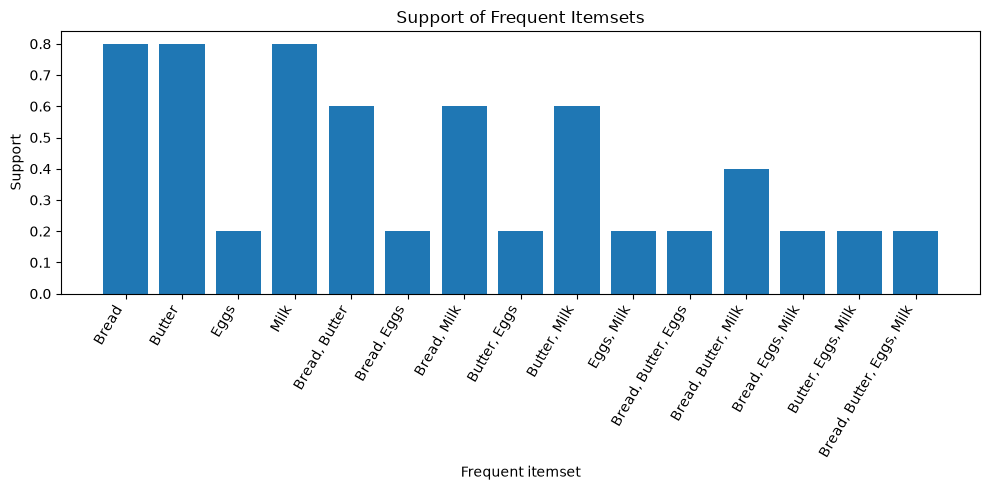

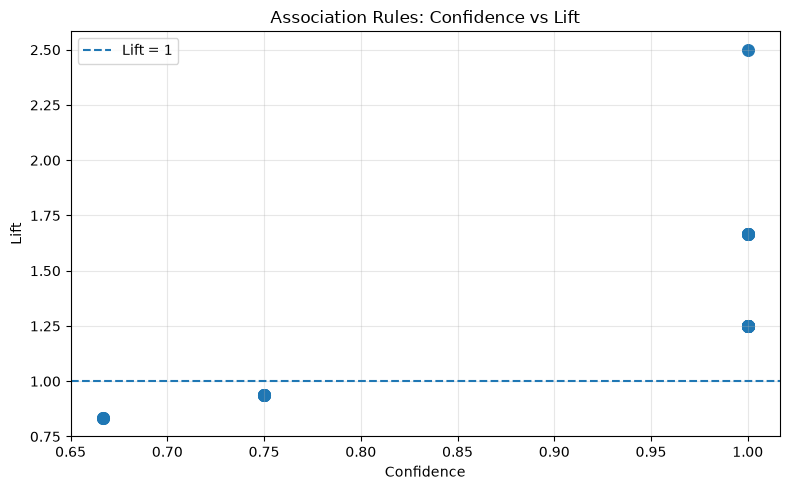

In [8]:
# Support of frequent itemsets
plot_itemsets = apriori(
    encoded_df,
    min_support=MIN_SUPPORT,
    use_colnames=True
).copy()

plot_itemsets["itemset_label"] = plot_itemsets["itemsets"].apply(
    lambda x: ", ".join(sorted(x))
)

plt.figure(figsize=(10, 5))
plt.bar(plot_itemsets["itemset_label"], plot_itemsets["support"])
plt.xlabel("Frequent itemset")
plt.ylabel("Support")
plt.title("Support of Frequent Itemsets")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

# Confidence versus lift for generated rules
if not rules.empty:
    plt.figure(figsize=(8, 5))
    plt.scatter(rules["confidence"], rules["lift"], s=70)
    plt.axhline(y=1, linestyle="--", label="Lift = 1")
    plt.xlabel("Confidence")
    plt.ylabel("Lift")
    plt.title("Association Rules: Confidence vs Lift")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Rule plot skipped because no rules were generated.")

## 10. Interpret the Generated Rules

A rule such as `Eggs → Milk` means that, in this dataset, transactions containing Eggs also contain Milk. Its support measures how often both items occur in the entire dataset; confidence measures how often Milk occurs among transactions containing Eggs; lift compares that confidence with Milk's overall frequency.

The following cell prints a few of the strongest rules by lift.

In [9]:
if not rules.empty:
    top_rules = rules.sort_values(
        by=["lift", "confidence", "support"],
        ascending=False
    ).head(10)

    for _, row in top_rules.iterrows():
        lhs = ", ".join(sorted(row["antecedents"]))
        rhs = ", ".join(sorted(row["consequents"]))
        lift_interpretation = (
            "positive association" if row["lift"] > 1
            else "approximately independent" if abs(row["lift"] - 1) < 1e-9
            else "negative association"
        )

        print(f"Rule: {lhs} -> {rhs}")
        print(
            f"  Support = {row['support']:.3f}, "
            f"Confidence = {row['confidence']:.3f}, "
            f"Lift = {row['lift']:.3f}"
        )
        print(f"  Interpretation: {lift_interpretation}.\n")
else:
    print("There are no rules to interpret at the current threshold.")

Rule: Eggs -> Bread, Butter, Milk
  Support = 0.200, Confidence = 1.000, Lift = 2.500
  Interpretation: positive association.

Rule: Eggs -> Bread, Butter
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Eggs -> Bread, Milk
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Eggs -> Butter, Milk
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Butter, Eggs -> Bread, Milk
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Eggs, Milk -> Bread, Butter
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Bread, Eggs -> Butter, Milk
  Support = 0.200, Confidence = 1.000, Lift = 1.667
  Interpretation: positive association.

Rule: Eggs -> Bread
  Support = 0.200, Confidence = 1.000, Lift = 1.250
  Interpretation: positive association.

Rule: Eggs -> Butte

## 11. Test Cases / Validation

The following checks validate that the dataset was loaded, one-hot encoding was performed, frequent itemsets were found, rules were generated, and evaluation metrics are available.

In [10]:
# Test Case 1: Load transaction dataset
assert len(transactions) == 5
print("PASS - Transaction dataset loaded successfully.")

# Test Case 2: One-hot encode data
assert encoded_df.shape[0] == 5
assert set(encoded_df.columns) == {"Milk", "Bread", "Butter", "Eggs"}
print("PASS - One-hot encoded dataset generated.")

# Test Case 3: Apply Apriori
assert not frequent_itemsets_for_rules.empty
print("PASS - Frequent itemsets identified.")

# Test Case 4: Generate association rules
assert not rules.empty
print("PASS - Association rules generated.")

# Test Case 5: Display support, confidence, and lift
required_metrics = {"support", "confidence", "lift"}
assert required_metrics.issubset(rules.columns)
print("PASS - Support, confidence, and lift are available.")

print("\nAll test cases passed.")

PASS - Transaction dataset loaded successfully.
PASS - One-hot encoded dataset generated.
PASS - Frequent itemsets identified.
PASS - Association rules generated.
PASS - Support, confidence, and lift are available.

All test cases passed.


# 12. Exercises / Assignments

## Exercise 1: Change the minimum support value

Run Apriori with a higher support threshold (0.40). Compare the itemsets with those found using 0.20. Itemsets that occur in only one transaction should disappear at a 0.40 threshold.

In [11]:
higher_support = 0.40

frequent_itemsets_high_support = apriori(
    encoded_df,
    min_support=higher_support,
    use_colnames=True
)

frequent_itemsets_high_support["itemsets"] = frequent_itemsets_high_support["itemsets"].apply(
    lambda x: ", ".join(sorted(x))
)

display(frequent_itemsets_high_support.sort_values(
    by=["support", "itemsets"], ascending=[False, True]
).reset_index(drop=True))

print("Itemsets at support 0.20:", len(frequent_itemsets_for_rules))
print("Itemsets at support 0.40:", len(frequent_itemsets_high_support))

,support,itemsets
0,0.8,Bread
1,0.8,Butter
2,0.8,Milk
3,0.6,"Bread, Butter"
4,0.6,"Bread, Milk"
5,0.6,"Butter, Milk"
6,0.4,"Bread, Butter, Milk"


Itemsets at support 0.20: 15
Itemsets at support 0.40: 7


## Exercise 2: Generate rules with a higher confidence threshold

Increase the confidence threshold to 0.80. Fewer rules (or possibly no rules) may satisfy the stricter requirement.

In [12]:
higher_confidence = 0.80

rules_high_confidence = association_rules(
    frequent_itemsets_for_rules,
    metric="confidence",
    min_threshold=higher_confidence
)

if rules_high_confidence.empty:
    print("No rules satisfy confidence >=", higher_confidence)
else:
    rules_high_confidence_display = rules_high_confidence[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ].copy()
    rules_high_confidence_display["antecedents"] = rules_high_confidence_display["antecedents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    rules_high_confidence_display["consequents"] = rules_high_confidence_display["consequents"].apply(
        lambda x: ", ".join(sorted(x))
    )
    display(rules_high_confidence_display.round(3))

,antecedents,consequents,support,confidence,lift
0,Eggs,Bread,0.2,1.0,1.250
1,Eggs,Butter,0.2,1.0,1.250
2,Eggs,Milk,0.2,1.0,1.250
3,"Butter, Eggs",Bread,0.2,1.0,1.250
4,"Bread, Eggs",Butter,0.2,1.0,1.250
5,Eggs,"Bread, Butter",0.2,1.0,1.667
6,"Eggs, Milk",Bread,0.2,1.0,1.250
7,"Bread, Eggs",Milk,0.2,1.0,1.250
8,Eggs,"Bread, Milk",0.2,1.0,1.667
9,"Butter, Eggs",Milk,0.2,1.0,1.250


## Exercise 3: Add new transactions and compare frequent itemsets

Two additional transactions are added below. The updated dataset is encoded and mined using the same thresholds. Compare its frequent itemsets with the original results.

In [13]:
updated_transactions = transactions + [
    ["Milk", "Bread", "Eggs"],       # T6
    ["Bread", "Butter", "Eggs"]      # T7
]

updated_te = TransactionEncoder()
updated_array = updated_te.fit(updated_transactions).transform(updated_transactions)
updated_encoded_df = pd.DataFrame(updated_array, columns=updated_te.columns_)

updated_frequent_itemsets = apriori(
    updated_encoded_df,
    min_support=MIN_SUPPORT,
    use_colnames=True
)

updated_frequent_itemsets["itemsets"] = updated_frequent_itemsets["itemsets"].apply(
    lambda x: ", ".join(sorted(x))
)

print("Updated transaction dataset:")
display(pd.DataFrame({
    "Transaction ID": [f"T{i+1}" for i in range(len(updated_transactions))],
    "Items Purchased": [", ".join(x) for x in updated_transactions]
}))

print("Frequent itemsets after adding two transactions:")
display(updated_frequent_itemsets.sort_values(
    by=["support", "itemsets"], ascending=[False, True]
).reset_index(drop=True))

Updated transaction dataset:


,Transaction ID,Items Purchased
0,T1,"Milk, Bread, Butter"
1,T2,"Bread, Butter"
2,T3,"Milk, Bread"
3,T4,"Milk, Butter"
4,T5,"Milk, Bread, Butter, Eggs"
5,T6,"Milk, Bread, Eggs"
6,T7,"Bread, Butter, Eggs"


Frequent itemsets after adding two transactions:


,support,itemsets
0,0.857143,Bread
1,0.714286,Butter
2,0.714286,Milk
3,0.571429,"Bread, Butter"
4,0.571429,"Bread, Milk"
5,0.428571,"Bread, Eggs"
6,0.428571,"Butter, Milk"
7,0.428571,Eggs
8,0.285714,"Bread, Butter, Eggs"
9,0.285714,"Bread, Butter, Milk"


## Exercise 4: Identify the rule with the highest lift

The rule with the highest lift is not necessarily the rule with the highest confidence. The next cell identifies it and prints all three main metrics.

In [14]:
if rules.empty:
    print("No rules are available. Lower the confidence threshold or minimum support.")
else:
    highest_lift_rule = rules.loc[rules["lift"].idxmax()]

    print(
        "Highest-lift rule:",
        f"{', '.join(sorted(highest_lift_rule['antecedents']))} "
        f"-> {', '.join(sorted(highest_lift_rule['consequents']))}"
    )
    print(f"Support:    {highest_lift_rule['support']:.3f}")
    print(f"Confidence: {highest_lift_rule['confidence']:.3f}")
    print(f"Lift:       {highest_lift_rule['lift']:.3f}")

Highest-lift rule: Eggs -> Bread, Butter, Milk
Support:    0.200
Confidence: 1.000
Lift:       2.500


## Exercise 5: Explain support, confidence, and lift

Write your observations in the space below, then compare them with the guiding points.

1. **Support** tells how common an itemset or the full rule is across all transactions. A low-support pattern may be rare even if its confidence is high.
2. **Confidence** tells how often the consequent appears when the antecedent appears. It is directional: `A → B` and `B → A` can have different confidence values.
3. **Lift** compares confidence with the consequent's baseline frequency. Lift greater than 1 means the consequent is more likely when the antecedent is present than it is overall.

### Important observation for this sample
Eggs occurs in only one of the five original transactions. Therefore, Eggs-related itemsets have support 0.20. Since Eggs appears with Milk, Bread, and Butter in that transaction, rules from Eggs to those items can have confidence 1.00. However, support and lift must still be checked before interpreting such a rule as a useful pattern. One observation from one transaction is not strong real-world evidence.

**Your observations:**

- Support:
- Confidence:
- Lift:
- Rule with the highest lift:
- What changed when minimum support was increased?
- What changed when minimum confidence was increased?


## 13. Experimental Observation and Result

After running all cells, record the following:

- The transaction data was converted into one-hot encoded Boolean form.
- Apriori identified itemsets meeting the selected minimum support.
- Association rules were generated using the selected minimum confidence.
- Support, confidence, and lift were calculated for the generated rules.
- Changing support and confidence thresholds changed the number of itemsets and rules.
- Adding transactions changed itemset support values and could change which itemsets qualified as frequent.

## 14. Conclusion

The experiment demonstrated frequent itemset mining and association rule generation using the Apriori algorithm. Support, confidence, and lift were used to evaluate the discovered relationships. The exercise also showed how mining thresholds and changes to the transaction database affect the resulting itemsets and rules.

## 15. Practical Notes

- Run the installation cell only when required.
- Run cells from top to bottom so that variables are defined before they are used.
- The results depend on the selected minimum support and confidence thresholds.
- A high confidence value does not automatically imply a strong association; inspect lift as well.
